Salvando DataFrames de Barras, Cargas e Linhas com Pickle

In [2]:
import pandas as pd
import py_dss_interface
from py_dss_toolkit import dss_tools

dss_file = r"C:\Dados_teste\OpenDSS\GWO\Alim_Meia_Ponte_5_ORIGINAL\Master_DU01_2021126072_5002086_NTMBSR1PVTTR.dss"

dss = py_dss_interface.DSS()

dss_tools.update_dss(dss)

dss.text(f"compile [{dss_file}]")
dss.text("buscoords buscoords.csv")

buses_df = dss_tools.model.buses_df
trafo_df = dss_tools.model.transformers_df
lines_df = dss_tools.model.lines_df
loads_df = dss_tools.model.loads_df

loads_df["kw"] = pd.to_numeric(loads_df["kw"], errors="coerce")
loads_df["kv"] = pd.to_numeric(loads_df["kv"], errors="coerce")

buses_df.to_pickle("original_buses_df.pkl")
loads_df.to_pickle("original_loads_df.pkl")
lines_df.to_pickle("original_lines_df.pkl")
trafo_df.to_pickle("original_trafo_df.pkl")

Preparação OpenDSS

In [3]:
import pandas as pd
import py_dss_interface
from py_dss_toolkit import dss_tools

dss_file = r"C:\Dados_teste\OpenDSS\GWO\Alim_Meia_Ponte_5_ORIGINAL\Master_DU01_2021126072_5002086_NTMBSR1PVTTR.dss"

dss = py_dss_interface.DSS()

dss_tools.update_dss(dss)

dss.text(f"compile [{dss_file}]")
dss.text("buscoords buscoords.csv")

def decide_element(bus: str, buses_df: pd.DataFrame, trafo_df: pd.DataFrame, lines_df: pd.DataFrame):
    bus = bus.split(".")[0]
    elements_query = buses_df.query(f"name == '{bus}'")["all_pde_active_bus"].iloc[0]

    distance = 1e6
    for element in elements_query:
        element_type, element_name = element.split(".")

        if element_type == "Line":
            segment_df = lines_df.query(f"name == '{element_name}'")

            element_bus = segment_df["bus_name"].iloc[0]
            distance_bus = buses_df.query(f"name == '{element_bus}'")["distance"].iloc[0]

            if "mt" in element_name:
                kv = 13.8

            elif "bt" in element_name:
                kv = 0.38

            else:
                continue

        elif element_type == "Transformer":
            element_bus = trafo_df.query(f"name == '{element_name}'")["bus_name"].iloc[0]
            distance_bus = buses_df.query(f"name == '{element_bus}'")["distance"].iloc[0]
            kv = trafo_df.query(f"name == '{element_name}'")["kv"].iloc[0]

        else:
            continue

        if distance_bus < distance:
            distance = distance_bus
            selected_element = element_name
            selected_element_type = element_type
            selected_kv = kv

    return selected_element_type, selected_element, selected_kv

def calc_rpf() -> float:
    soma = 0
    for name in dss.monitors.names:
        if "voltage" in name:
            continue

        if "battery" in name:
            continue

        dss.monitors.name = name
        monitor = dss.monitors.channel(1)

        soma += sum(x for x in monitor if x < 0)

    return soma

def calc_separated_rpf() -> tuple[float]:
    soma = 0
    soma_feeder = 0
    for name in dss.monitors.names:
        if "voltage" in name:
            continue

        if "battery" in name:
            continue

        dss.monitors.name = name
        monitor = dss.monitors.channel(1)

        if "feeder" in name:  
            soma_feeder += sum(x for x in monitor if x < 0)
            continue

        dss.monitors.name = name
        monitor = dss.monitors.channel(1)

        soma += sum(x for x in monitor if x < 0)

    return soma, soma_feeder

buses_df = pd.read_pickle("original_buses_df.pkl")
loads_df = pd.read_pickle("original_loads_df.pkl")
lines_df = pd.read_pickle("original_lines_df.pkl")
trafo_df = pd.read_pickle("original_trafo_df.pkl")

trafo_df["bus_name"] = trafo_df["bus"].str.split(".").str[0]
lines_df["bus_name"] = lines_df["bus1"].str.split(".").str[0]

buses_df = buses_df[["name", "distance", "all_pce_active_bus", "all_pde_active_bus"]]



Caso Base


,kwh,kvarh,zone kwh,zone losses kwh
0,124373.46653,63068.334783,115371.908738,9047.120175



Convergência das ações de controle:  1
Número de iterações de controle:  1

Caso Ótimo


,kwh,kvarh,zone kwh,zone losses kwh
0,0.032727,-403.860378,129625.717866,1041.734863


,Caso,Fluxo Reverso Total (kWh),Fluxo Reverso Trafos (kWh),Fluxo Reverso Alimentador,Fitness
0,Caso Base,0,0.00000,0.0,0.000000
1,Caso Ótimo,-0.00454,-0.00454,0.0,0.009081


Gráficos


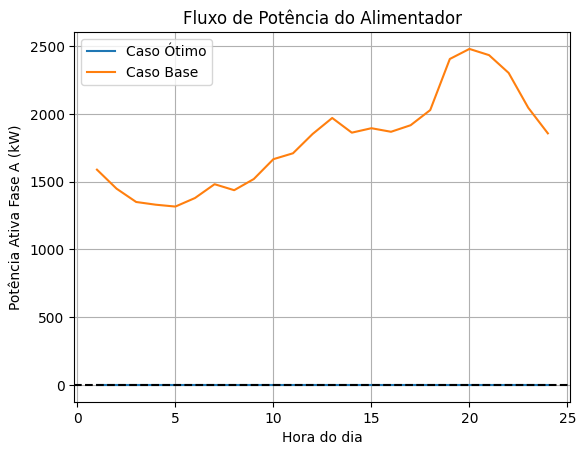

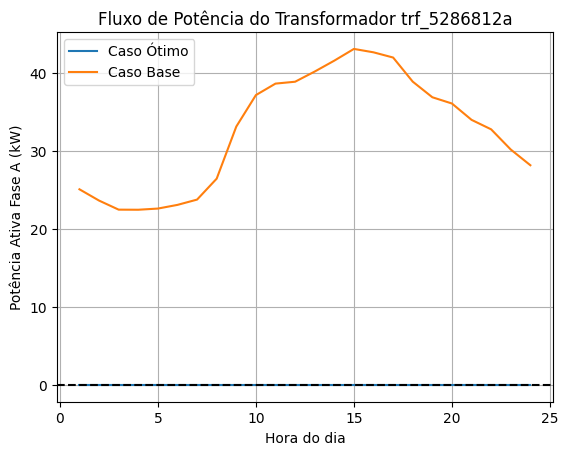

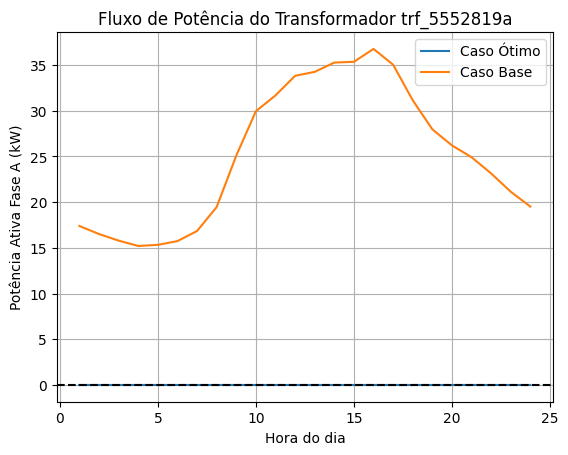

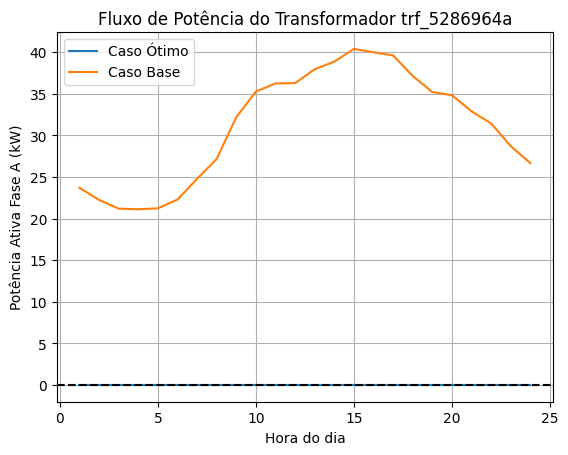

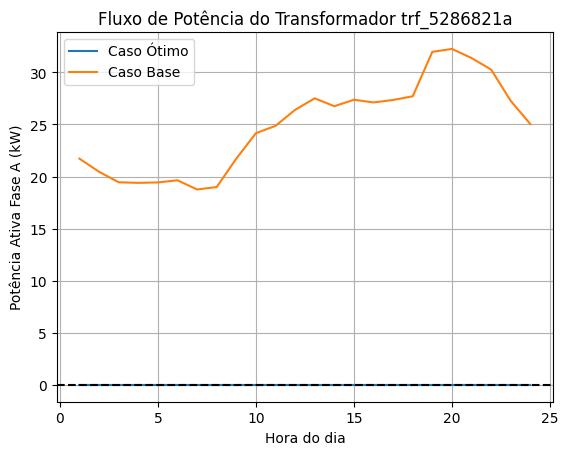

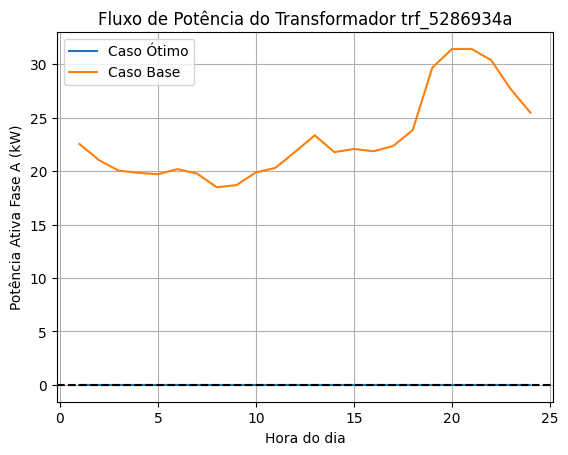

In [6]:
import py_dss_interface
from py_dss_toolkit import dss_tools
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

cases = ["Caso Base", "Caso Ótimo"]

solution_buses = ['82060485286861', '82049415002086', '15780030', '15356577', '82025765286821']

solution_powers = [480.83, 224.2, 72.0, 182.92, 154.16]

powers = solution_powers

dss_file = r"C:\Dados_teste\OpenDSS\GWO\Alim_Meia_Ponte_5_ORIGINAL\Master_DU01_2021126072_5002086_NTMBSR1PVTTR.dss"

dss = py_dss_interface.DSS()

dss_tools.update_dss(dss)

df_rpf = pd.DataFrame(columns=["Caso", "Fluxo Reverso Total (kWh)"])

voltage_dfs_base_case = {}

for case in cases:

    dss.text(f"compile [{dss_file}]")

    dss.text("Redirect 'PV_System_120_MeiaPonte.dss'")
    #dss.text("Redirect 'PVSystem_120_Irrad.dss")
    dss.text("buscoords buscoords.csv")

    if case == "Caso Ótimo":

        for i, (power, bus) in enumerate(zip(powers, solution_buses)):
            element_type, element_name, kv = decide_element(bus, buses_df, trafo_df, lines_df)
            pot = power

            dss.text(f"New Storage.Battery_{i} phases=3 bus1={bus} kv={kv} kWrated={pot} kWhrated={8*pot} dispmode=follow %stored=50")
            
            dss.text(f"New StorageController.SC_{i} element={element_type}.{element_name} terminal=1 modedis=peakShave elementList=[Battery_{i}]\n"
            f"~ MonPhase=AVG kwtarget=5 modecharge=peakShaveLow kwtargetLow=0\n\n")

            dss.text(f"New Monitor.Battery_{i} element=Storage.Battery_{i} mode=7")

    dss.text(f"buscoords BusCoords.csv")

    dss.text("set mode=daily")
    dss.text("set stepsize=1h")
    dss.text("set number=24")
    dss.text("set maxcontroliter=200")

    dss.solution.solve()

    energymeter_df = dss_tools.results.energymeters

    if case == "Caso Base":
        for name in dss.monitors.names:
            if not "voltage" in name:
                continue

            voltage_dfs_base_case[name] = dss_tools.results.monitor(name)

    elem_1, elem_2, elem_3, elem_4, elem_5 = "trf_5286812a", "trf_5552819a", "trf_5286964a", "trf_5286821a", "trf_5286934a"

    if case == "Caso Ótimo":
        print("\nConvergência das ações de controle: ", dss.solution.control_actions_done)
        print("Número de iterações de controle: ", dss.solution.control_iterations)

        df_optimal_feeder = dss_tools.results.monitor("feeder")
        df_optimal_trafo_1 = dss_tools.results.monitor(elem_1)
        df_optimal_trafo_2 = dss_tools.results.monitor(elem_2)
        df_optimal_trafo_3 = dss_tools.results.monitor(elem_3)
        df_optimal_trafo_4 = dss_tools.results.monitor(elem_4)
        df_optimal_trafo_5 = dss_tools.results.monitor(elem_5)

    elif case == "Caso Base":
        df_base_feeder = dss_tools.results.monitor("feeder")
        df_base_trafo_1 = dss_tools.results.monitor(elem_1)
        df_base_trafo_2 = dss_tools.results.monitor(elem_2)
        df_base_trafo_3  = dss_tools.results.monitor(elem_3)
        df_base_trafo_4  = dss_tools.results.monitor(elem_4)
        df_base_trafo_5  = dss_tools.results.monitor(elem_5)

    print(f"\n{case}")
    display(energymeter_df[["kwh", "kvarh", "zone kwh", "zone losses kwh"]])

    rpf = calc_rpf()
    rpf_transf, rpf_feeder = calc_separated_rpf()
    fitness = rpf_transf*2 + rpf_feeder  #w1 = 2
    
    df2 = pd.DataFrame(
        {
            "Caso": [case], 
            "Fluxo Reverso Total (kWh)": [rpf], 
            "Fluxo Reverso Trafos (kWh)": [rpf_transf], 
            "Fluxo Reverso Alimentador": [rpf_feeder],
            "Fitness": [abs(fitness)]
        }
    )

    df_rpf = pd.concat([df_rpf, df2], ignore_index=True)

#Fluxo reverso total
display(df_rpf)

#### Gráfico
print("Gráficos")

# Alimentador
plt.plot(df_optimal_feeder["Hour"], df_optimal_feeder[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_feeder["Hour"], df_base_feeder[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.grid(True)
plt.axhline(y=0, linestyle="--", color="black")
plt.title("Fluxo de Potência do Alimentador")
plt.show()

#Trafo 5286812a
plt.plot(df_optimal_trafo_1["Hour"], df_optimal_trafo_1[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_1["Hour"], df_base_trafo_1[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.grid(True)
plt.axhline(y=0, linestyle="--", color="black")
plt.title(f"Fluxo de Potência do Transformador {elem_1}")
plt.show()

#Trafo 5552819a

plt.plot(df_optimal_trafo_2["Hour"], df_optimal_trafo_2[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_2["Hour"], df_base_trafo_2[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.grid(True)
plt.axhline(y=0, linestyle="--", color="black")
plt.title(f"Fluxo de Potência do Transformador {elem_2}")
plt.show()

#Trafo 5286964a

plt.plot(df_optimal_trafo_3["Hour"], df_optimal_trafo_3[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_3["Hour"], df_base_trafo_3[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.axhline(y=0, linestyle="--", color="black")
plt.grid(True)
plt.title(f"Fluxo de Potência do Transformador {elem_3}")
plt.show()

#Trafo 5286821a

plt.plot(df_optimal_trafo_4["Hour"], df_optimal_trafo_4[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_4["Hour"], df_base_trafo_4[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.axhline(y=0, linestyle="--", color="black")
plt.grid(True)
plt.title(f"Fluxo de Potência do Transformador {elem_4}")
plt.show()

#Trafo 5286934a

plt.plot(df_optimal_trafo_5["Hour"], df_optimal_trafo_5[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_5["Hour"], df_base_trafo_5[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.axhline(y=0, linestyle="--", color="black")
plt.grid(True)
plt.title(f"Fluxo de Potência do Transformador {elem_5}")
plt.show()

In [3]:
pvsystems_df = dss_tools.model.pvsystems_df
display(pvsystems_df)

,name,phases,bus1,kv,irradiance,pmpp,%pmpp,temperature,pf,conn,...,safemode,dynamiceq,dynout,controlmode,amplimit,amplimitgain,spectrum,basefreq,enabled,like
0,pv_1,3,10008808838.1.2.3,12.47,1,86.7127,100,25,1,wye,...,No,,[],GFL,,,,60,true,
1,pv_2,3,10008808838.1.2.3,12.47,1,86.7127,100,25,1,wye,...,No,,[],GFL,,,,60,true,
2,pv_3,3,10028328165.1.2.3,12.47,1,45.3861,100,25,1,wye,...,No,,[],GFL,,,,60,true,
3,pv_4,3,10028328165.1.2.3,12.47,1,45.3861,100,25,1,wye,...,No,,[],GFL,,,,60,true,
4,pv_5,3,14939393.1.2.3,12.47,1,48.5052,100,25,1,wye,...,No,,[],GFL,,,,60,true,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,pv_116,3,14202566.1.2.3,12.47,1,11.7515,100,25,1,wye,...,No,,[],GFL,,,,60,true,
116,pv_117,3,14376192.1.2.3,12.47,1,11.6139,100,25,1,wye,...,No,,[],GFL,,,,60,true,
117,pv_118,3,14376192.1.2.3,12.47,1,11.6139,100,25,1,wye,...,No,,[],GFL,,,,60,true,
118,pv_119,3,10018508543.1.2.3,12.47,1,11.5142,100,25,1,wye,...,No,,[],GFL,,,,60,true,
